# `stochastics.baseline` — stochastic processes

```python
X = process(t=100, n=1000)     # t time steps, n runs; horizon T = 1, so dt = T / t
X.randomwalk()                 # generate (returns the Paths, and X remembers them)
X.mean, X.std, X.var           # statistics across runs, as Series over time
X.plot()                       # paths on the left, terminal distribution on the right
```

Every process carries its **theory** (mean, variance, and the terminal density where known), so plots overlay
theory on simulation and `describe()` compares them. Exact transition sampling is used wherever it exists;
Euler–Maruyama and Milstein are there for any SDE and for comparing discretisation error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stochastics.baseline import *

## 1. Random walk — your API
Each step is +1 with probability p and −1 otherwise. After k steps the mean is k(2p − 1) and the variance
4p(1 − p)k; the orange dots on the right are the exact binomial probabilities.

In [2]:
X = process(t=100, n=1000, seed=1)
X.randomwalk()
pd.DataFrame({'mean': X.mean, 'std': X.std, 'var': X.var}).iloc[::20]

,mean,std,var
time,,,
0.0,0.000,0.000000,0.000000
0.2,0.296,4.508293,20.324709
0.4,0.162,6.256589,39.144901
0.6,0.192,7.639732,58.365502
0.8,0.156,8.869178,78.662326
1.0,0.100,10.159390,103.213213


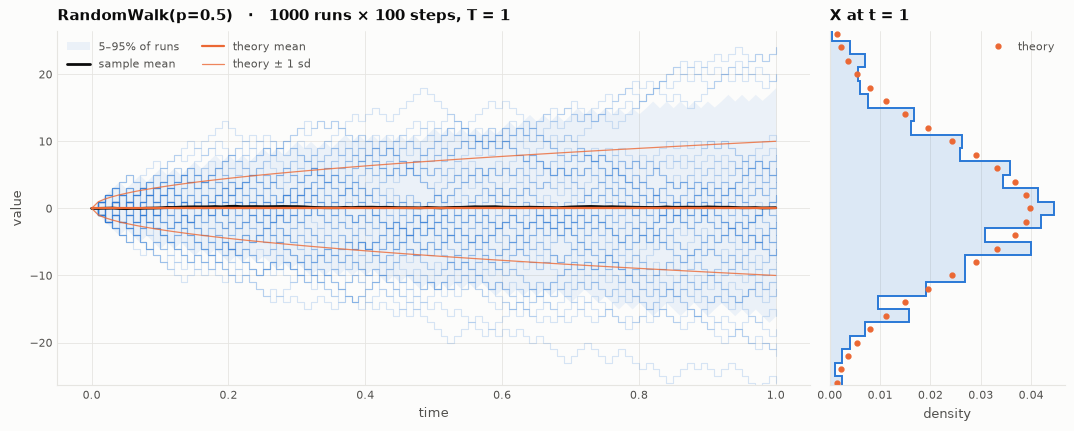

In [3]:
X.plot()

## 2. The core continuous processes

| process | SDE | use |
|---|---|---|
| Wiener / Brownian motion | dW, increments N(0, dt) | the building block of everything below |
| arithmetic BM | dX = μ dt + σ dW | additive noise with drift; normal at every t |
| geometric BM | dX = μX dt + σX dW | prices: positive, lognormal, returns independent of level |
| Ornstein–Uhlenbeck | dX = θ(μ − X) dt + σ dW | mean reversion (spreads, rates, Hurst < 0.5 behaviour) |
| CIR | dX = κ(θ − X) dt + σ√X dW | mean-reverting and non-negative (rates, variance) |
| Poisson | N(t) jumps by 1 at rate λ | counting arrivals (orders, defaults, events) |

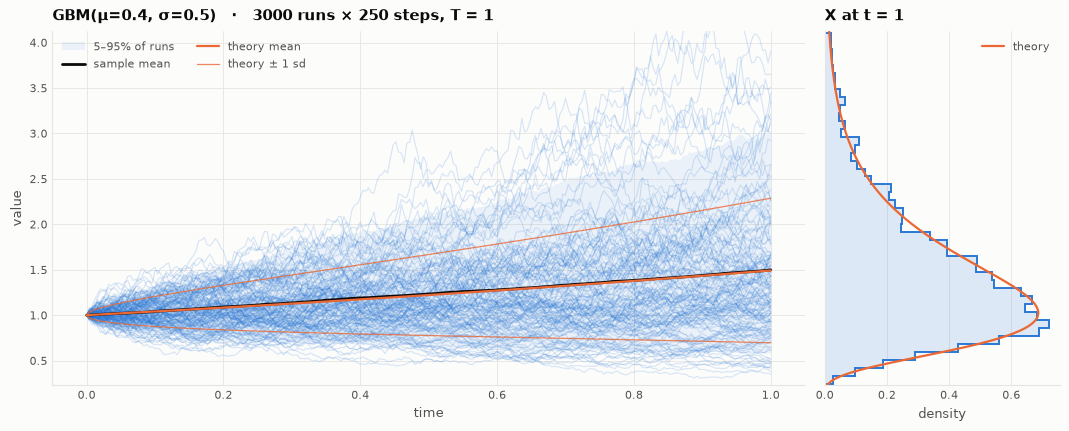

In [4]:
P = process(t=250, n=3000, seed=7)
P.gbm(mu=0.4, sigma=0.5).plot()

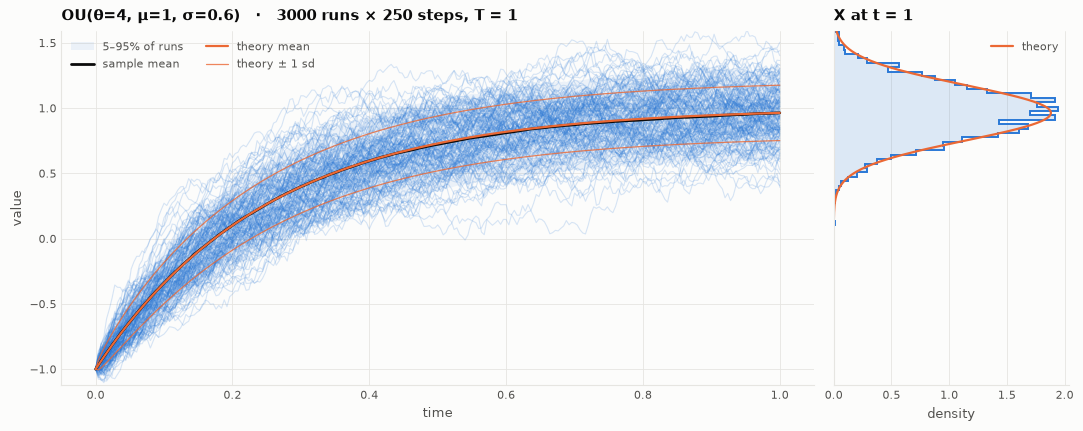

In [5]:
P.ou(theta=4, mu=1.0, sigma=0.6, x0=-1).plot()

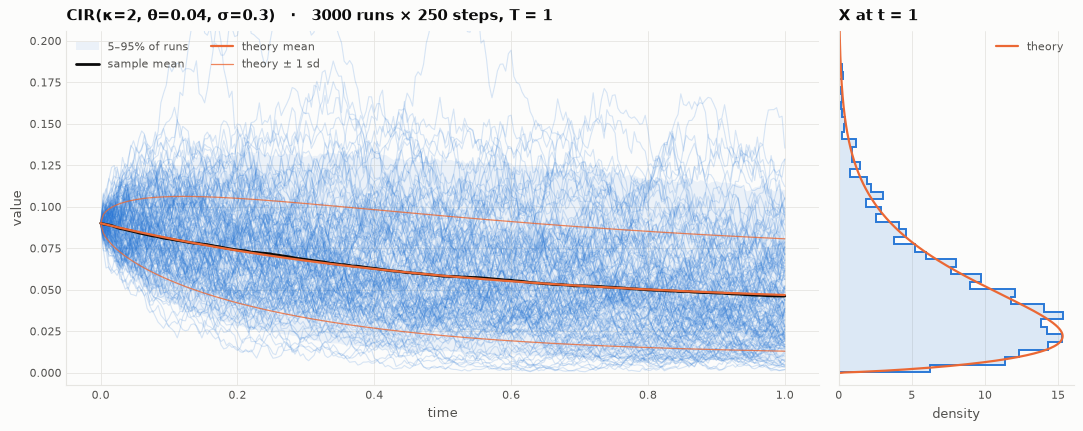

In [6]:
P.cir(kappa=2, theta=0.04, sigma=0.3, x0=0.09).plot()

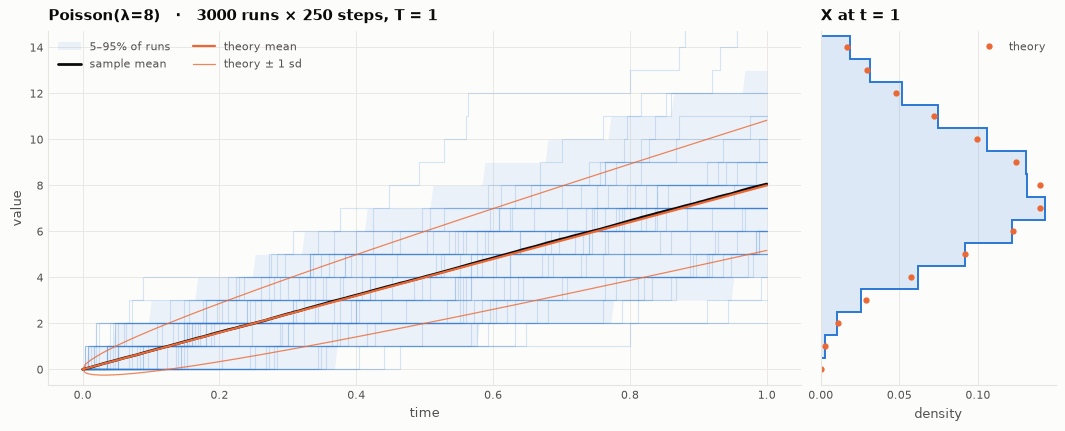

In [7]:
P.poisson(rate=8).plot()

`describe()` puts simulated terminal moments next to theory; `z (mean)` is the sample mean's distance from the
theoretical mean in standard errors (|z| < 3 is what sampling noise looks like).

In [8]:
pd.concat({name: getattr(P, name)(**kw).describe()[['simulated', 'theory']].loc[['mean', 'std']]
           for name, kw in [('wiener', {}), ('abm', dict(mu=2, sigma=0.5)), ('gbm', dict(mu=0.4, sigma=0.5)),
                            ('ou', dict(theta=4, mu=1, sigma=0.6)), ('cir', {}), ('poisson', dict(rate=8))]})

simulated    theory
        Wiener at t=1  (3000 runs)                     
wiener  mean                        -0.006378  0.000000
        std                          0.994622  1.000000
abm     mean                         1.997545  2.000000
        std                          0.510779  0.500000
gbm     mean                         1.495628  1.491825
        std                          0.803969  0.795054
ou      mean                         0.977949  0.981684
        std                          0.215502  0.212096
cir     mean                         0.040992  0.040000
        std                          0.019836  0.019816
poisson mean                         7.982667  8.000000
        std                          2.817152  2.828427

## 3. Euler–Maruyama and Milstein for any SDE

`sde(drift, diffusion, x0, scheme=...)` solves dX = a(t, X) dt + b(t, X) dW for any vectorised a and b.
Below, both schemes integrate GBM with the *same* Brownian increments as the exact solution, so the pathwise
error is pure discretisation error: Euler converges like √dt, Milstein like dt.

In [9]:
rows = []
for steps in (8, 16, 32, 64, 128, 256):
    Q = process(t=steps, n=4000, seed=3)
    noise = Q.noise()
    exact = Q.gbm(0.5, 0.8, noise=noise).final
    for scheme in ('euler', 'milstein'):
        approx = Q.sde(lambda t, x: 0.5 * x, lambda t, x: 0.8 * x, x0=1.0, noise=noise, scheme=scheme).final
        rows.append({'dt': 1 / steps, 'scheme': scheme, 'strong error': np.mean(np.abs(approx - exact))})
err = pd.DataFrame(rows).pivot(index='dt', columns='scheme', values='strong error')
slopes = {c: round(float(np.polyfit(np.log(err.index), np.log(err[c]), 1)[0]), 2) for c in err}
ax = err.plot(loglog=True, marker='o', figsize=(6, 4), title='Strong error vs dt  (slope = order)')
ax.set_ylabel('E|X_approx − X_exact| at T')
print('estimated orders:', slopes)

estimated orders: {'euler': 0.48, 'milstein': 0.98}


## 4. More processes worth having

* **Brownian bridge** — BM pinned at both ends (interpolation, barrier crossing between observations).
* **Compound Poisson / Merton jump diffusion** — GBM plus lognormal jumps: fat tails and gaps.
* **Heston** — price with its own mean-reverting variance; ρ < 0 gives the leverage effect.
* **Fractional BM** — memory: Hurst H > ½ trends, H < ½ mean-reverts ("rough").
* **Hawkes** — self-exciting arrivals: each event raises the chance of the next (order flow, trade clustering).
* **Regime switching** — drift and volatility follow a hidden Markov chain (calm ↔ stressed).
* **GARCH(1,1)** — volatility clustering in discrete returns.

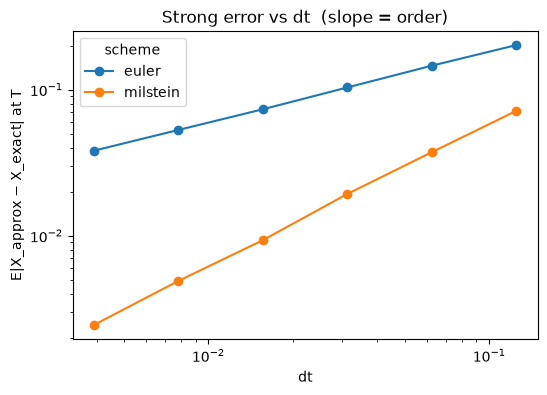

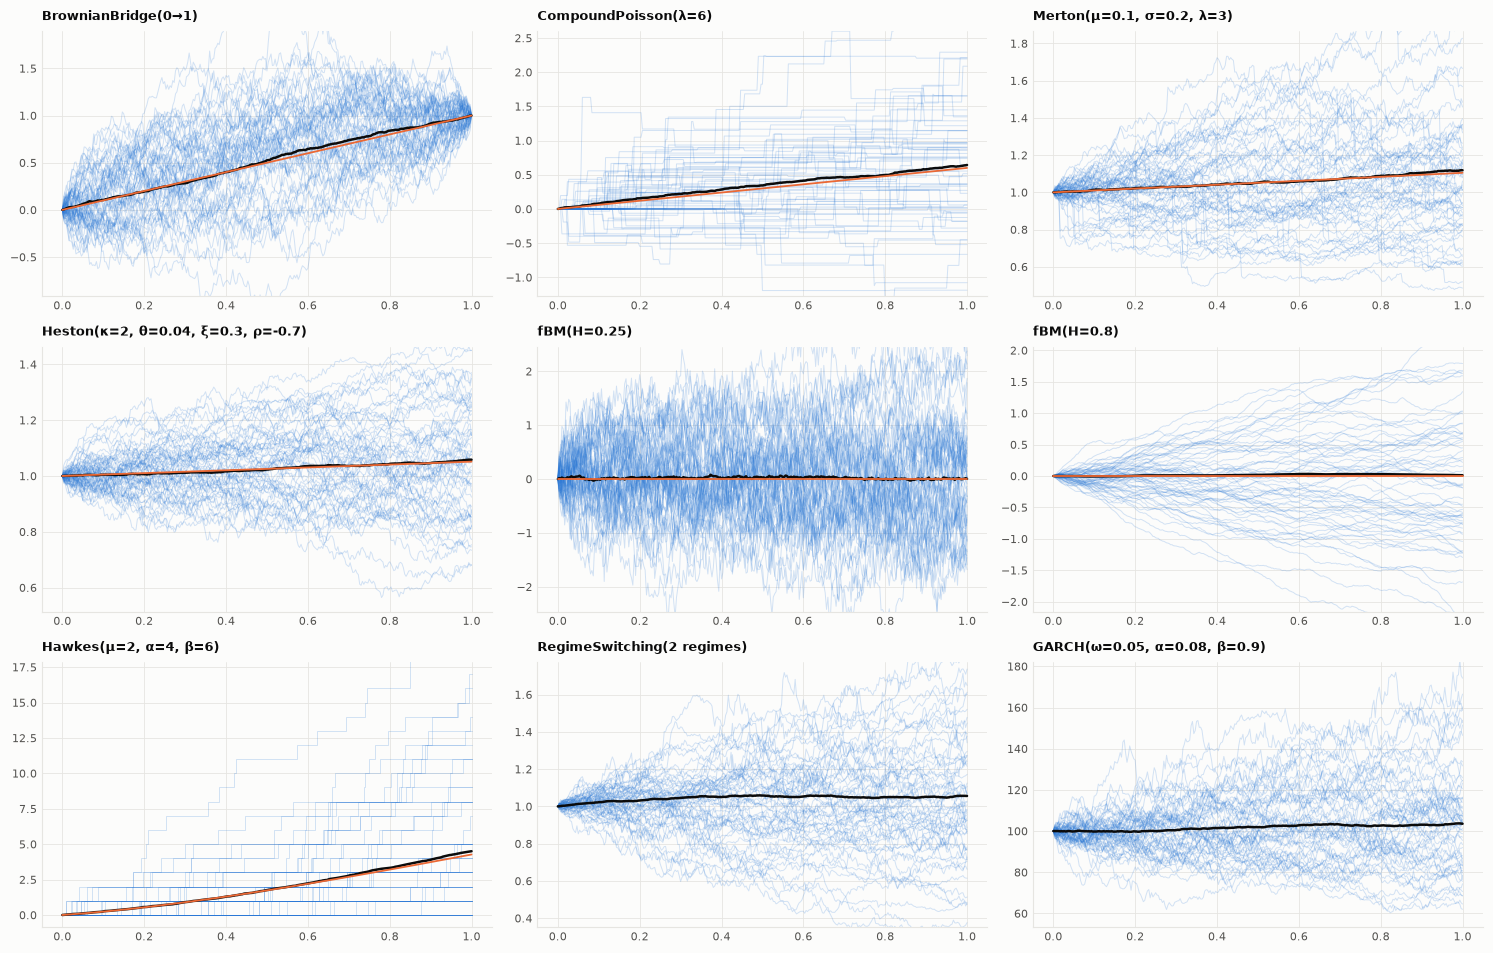

In [10]:
Q = process(t=300, n=400, seed=11)
plot_many([Q.brownian_bridge(0, 1), Q.compound_poisson(rate=6, jump_mean=0.1, jump_std=0.3),
           Q.merton(mu=0.1, sigma=0.2, jump_rate=3, jump_mean=-0.1, jump_std=0.1),
           Q.heston(), Q.fbm(hurst=0.25), Q.fbm(hurst=0.8),
           Q.hawkes(mu=2, alpha=4, beta=6), Q.regime_switching(), Q.garch()])

In [11]:
F = process(t=1000, n=500, seed=4)
pd.DataFrame({'H (true)': [0.25, 0.5, 0.75],
              'H (estimated from paths)': [F.fbm(h).hurst() for h in (0.25, 0.5, 0.75)]})

,H (true),H (estimated from paths)
0,0.25,0.250066
1,0.50,0.499610
2,0.75,0.748735


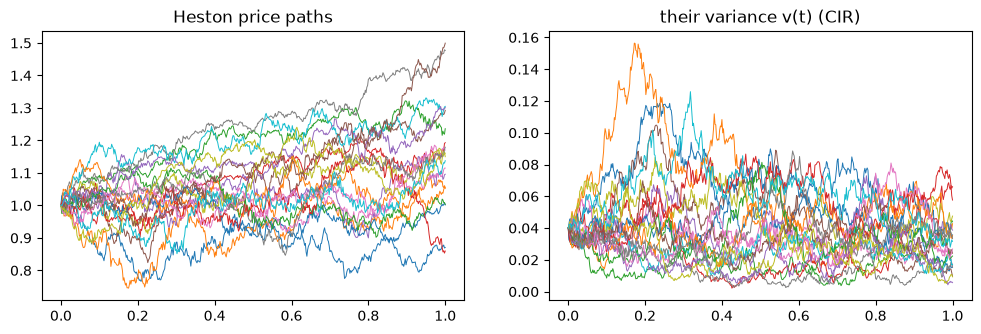

corr(return, change in variance) = -0.7


In [12]:
H = process(t=500, n=2000, seed=5).heston(rho=-0.7)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for i in range(20):
    axs[0].plot(H.times, H.values[i], lw=0.7)
    axs[1].plot(H.times, H.extras['variance'].values[i], lw=0.7)
axs[0].set_title('Heston price paths'); axs[1].set_title('their variance v(t) (CIR)')
plt.show()
dv = np.diff(H.extras['variance'].values, axis=1)
print('corr(return, change in variance) =', round(np.corrcoef(H.log_returns.ravel(), dv.ravel())[0, 1], 3))

## 5. Combining processes: weighted sums are convolutions

`0.5*X + 0.2*Y + 0.3*Z` builds a new set of paths, run by run (a portfolio of the three). When X, Y and Z are
driven by **independent** noise:

* means add: E[S] = 0.5 E[X] + 0.2 E[Y] + 0.3 E[Z];
* variances add with squared weights;
* the density of S at T is the **convolution** of the densities of 0.5X_T, 0.2Y_T and 0.3Z_T. The package
  computes it numerically (exact per-bin probabilities, then FFT convolution) and overlays it in orange.

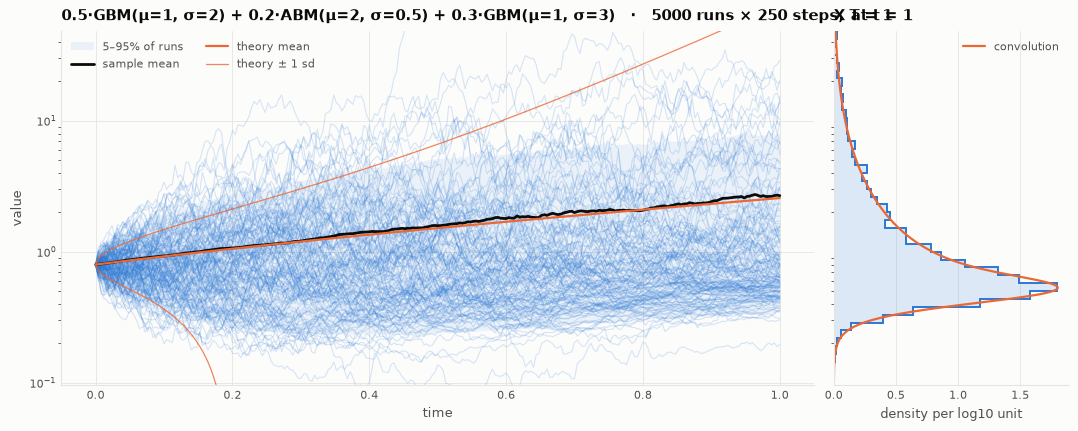

,simulated,theory,z (mean)
"0.5·GBM(μ=1, σ=2) + 0.2·ABM(μ=2, σ=0.5) + 0.3·GBM(μ=1, σ=3) at t=1 (5000 runs)",,,
mean,2.685983,2.574625,0.526143
std,14.965859,74.074474,NaN
var,223.976934,5487.027674,NaN
skew,28.967158,NaN,NaN
excess kurtosis,1174.931808,NaN,NaN
min,0.076767,NaN,NaN
median,0.736104,NaN,NaN
max,719.347576,NaN,NaN


In [13]:
P = process(t=250, n=5000, seed=1)
X = P.gbm(mu=1, sigma=2)        # 'geometric Brownian motion with mean 1 and std 2'
Y = P.abm(mu=2, sigma=0.5)      # 'arithmetic Brownian motion with mean 2, std 0.5'
Z = P.gbm(mu=1, sigma=3)
S = 0.5 * X + 0.2 * Y + 0.3 * Z   # same as combine([0.5, 0.2, 0.3], [X, Y, Z])
S.plot()
S.describe()

GBM with σ = 2–3 is extremely skewed (median far below mean), so the sample mean converges slowly; the
theory column is the exact value. The plot switches to a log axis for heavy tails and shows the density per
log₁₀ unit.

### Sum vs mixture
A **mixture** is a different blend: each run *is* X with probability 0.5, Y with 0.2, Z with 0.3. Same mean,
but its density is the weighted *average* of the component densities, not their convolution. With three
normal components the difference is stark: the sum is one narrow normal, the mixture is three humps.

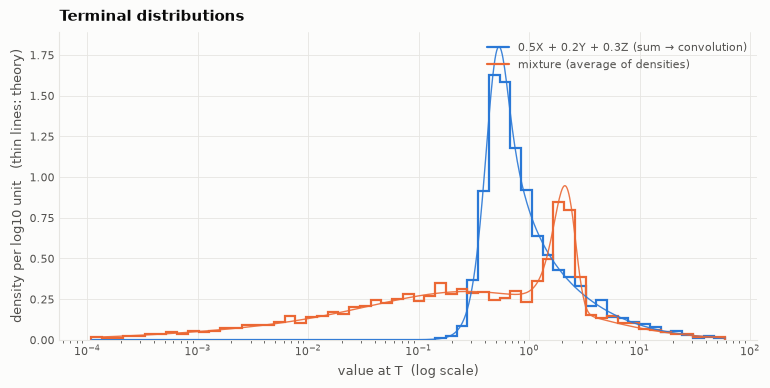

In [14]:
M = mixture([0.5, 0.2, 0.3], [X, Y, Z], seed=3)
plot_terminal(S, M, labels=['0.5X + 0.2Y + 0.3Z (sum → convolution)', 'mixture (average of densities)'])

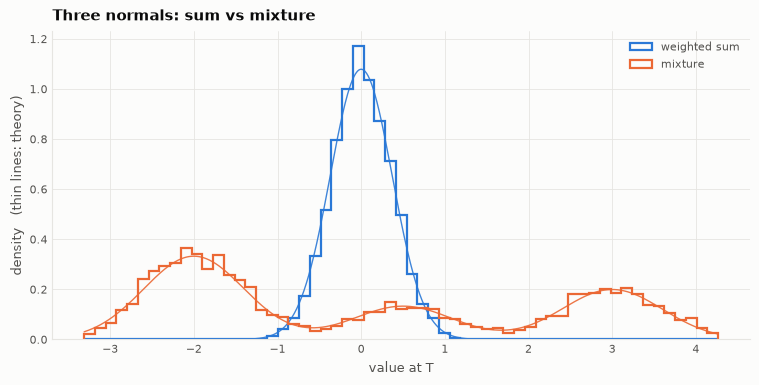

In [15]:
Q = process(t=200, n=5000, seed=2)
A, B, C = Q.abm(-2, 0.6), Q.abm(0.5, 0.6), Q.abm(3, 0.6)
plot_terminal(combine([0.5, 0.2, 0.3], [A, B, C]), mixture([0.5, 0.2, 0.3], [A, B, C], seed=1),
              labels=['weighted sum', 'mixture'], title='Three normals: sum vs mixture')

### Correlated drivers
Independence is what makes the variances add. With shared or correlated noise the package knows the
variance is no longer additive (`S.independent` is False and the theory variance is dropped), and
`process.correlated(k, rho)` gives correlated Brownian drivers for building dependent processes.

In [16]:
Q = process(t=250, n=20000, seed=8)
rows = []
for rho in (-0.9, -0.5, 0.0, 0.5, 0.9):
    a, b = Q.correlated(2, rho)
    port = 0.5 * Q.gbm(0.1, 0.3, noise=a) + 0.5 * Q.gbm(0.1, 0.3, noise=b)
    rows.append({'rho': rho, 'portfolio sd': port.final.std(), 'independent?': port.independent})
pd.DataFrame(rows).set_index('rho')

,portfolio sd,independent?
rho,,
-0.9,0.099806,False
-0.5,0.176522,False
0.0,0.241710,True
0.5,0.295247,False
0.9,0.333329,False


## 6. Path analytics

In [17]:
G = process(t=500, n=5000, seed=9).gbm(mu=0.1, sigma=0.3)
hit = G.first_passage(1.5)
dd = G.max_drawdown()
pd.Series({'P(hit 1.5 before T)': np.mean(~np.isnan(hit)), 'median time to hit': np.nanmedian(hit),
           'median max drawdown': np.median(dd), '95% max drawdown': np.quantile(dd, 0.95),
           'lag-1 autocorrelation of increments': G.acf(5).iloc[1]})

P(hit 1.5 before T)                    0.214200
median time to hit                     0.642000
median max drawdown                    0.265611
95% max drawdown                       0.461181
lag-1 autocorrelation of increments   -0.002792
dtype: float64